# Tệp: notebooks/01_data_quality_eda.ipynb
# Mục đích: Đánh giá chất lượng dữ liệu và khám phá MOOC-Radar bằng tiếng Việt, độc lập với huấn luyện.

# Đánh giá chất lượng dữ liệu và EDA — MOOC-Radar

Notebook đọc dữ liệu gốc theo từng chuỗi sinh viên, không sửa hoặc xóa bản ghi. Kết quả được lưu trong một thư mục `artifacts/eda_<run_id>/` mới để dùng cho báo cáo Modern MIS. Chạy notebook này **trước** bước chuẩn hóa và huấn luyện.


## 1. Mục tiêu phân tích

Kiểm tra cấu trúc file, missing values, trùng lặp, timestamp, liên kết problem–concept–course và độ bao phủ nhãn Bloom/video. Các biểu đồ mô tả dữ liệu quan sát; chúng không chứng minh nguyên nhân hay hiệu quả học tập. Chế độ `sample` thuận tiện để thử nhanh, còn `full` dùng toàn bộ file fine cục bộ.


In [4]:
from pathlib import Path
import csv
import json
import os
import subprocess
import sys

from IPython.display import Image, Markdown, display


In [5]:
from pathlib import Path
import subprocess
import os

ROOT = Path("/content/Personalized-Learning-Path")
if not ROOT.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/DuoChip/Personalized-Learning-Path.git",
        str(ROOT),
    ], check=True)

assert (ROOT / "src/moocradar/eda.py").is_file(), "Repo trên GitHub chưa có thư mục src/"
assert (ROOT / "requirements.txt").is_file(), "Repo thiếu requirements.txt"

os.environ["MOOC_PROJECT_ROOT"] = str(ROOT)
os.environ["MOOC_DATA_ROOT"] = "/content/drive/MyDrive/MOOC-Radar/data/raw"
os.environ["MOOC_ARTIFACT_ROOT"] = "/content/drive/MyDrive/MOOC-Radar/artifacts"

## 2. Thư viện và cấu hình

Trên Colab, notebook mount Google Drive bằng cơ chế chính thức và cài dependencies từ dự án. Có thể đặt biến môi trường `MOOC_PROJECT_ROOT`, `MOOC_DATA_ROOT`, `MOOC_ARTIFACT_ROOT`; không cần sửa mã nguồn. Khi chạy local, notebook tự tìm thư mục gốc dự án từ thư mục hiện tại.


In [6]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    drive.mount("/content/drive")

local_candidates = [Path.cwd(), *Path.cwd().parents]
local_root = next((p for p in local_candidates if (p / "src/moocradar").is_dir()), None)
default_root = Path("/content/drive/MyDrive/Personalized_learning_path") if IN_COLAB else local_root
if default_root is None and "MOOC_PROJECT_ROOT" not in os.environ:
    raise FileNotFoundError("Đặt MOOC_PROJECT_ROOT tới thư mục dự án")
PROJECT_ROOT = Path(os.environ.get("MOOC_PROJECT_ROOT", str(default_root))).expanduser()
DATA_ROOT = Path(os.environ.get("MOOC_DATA_ROOT", str(PROJECT_ROOT / "data/raw"))).expanduser()
ARTIFACT_ROOT = Path(os.environ.get("MOOC_ARTIFACT_ROOT", str(PROJECT_ROOT / "artifacts"))).expanduser()
MODE = "sample"  # Đổi thành "full" để phân tích toàn bộ file fine.
SAMPLE_STUDENTS = 25
assert (PROJECT_ROOT / "src/moocradar/eda.py").is_file(), "Kiểm tra PROJECT_ROOT"
assert (DATA_ROOT / "problem.json").is_file(), "Kiểm tra DATA_ROOT"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(PROJECT_ROOT / "requirements.txt")], check=True)
import pandas as pd
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from moocradar.eda import inspect_files, inspect_schema, run_eda
print("Chế độ:", MODE, "| Dữ liệu:", DATA_ROOT)


Chế độ: sample | Dữ liệu: /content/drive/MyDrive/MOOC-Radar/data/raw


## 3. Khảo sát file và cấu trúc dữ liệu

Bảng đầu chỉ đọc metadata của file; bảng sau lấy **một** sự kiện mẫu từ từng JSON array và chỉ in tên trường/kiểu dữ liệu. Không hiển thị `user_id`, `log_id` hay nội dung câu hỏi dài. `problem.json` là JSON Lines; ba file tương tác là JSON array chứa các chuỗi `seq`.


In [8]:
file_table = pd.DataFrame(inspect_files(DATA_ROOT))
display(file_table)
display(pd.DataFrame(inspect_schema(DATA_ROOT)))


,file,exists,bytes,mib,format
0,problem.json,True,6715077,6.40,JSON Lines
1,student-problem-fine.json,True,152280456,145.23,JSON array of student sequences
2,student-problem-middle.json,True,201525773,192.19,JSON array of student sequences
3,student-problem-coarse.json,True,197158175,188.02,JSON array of student sequences


,dataset,field,types
0,student-problem-fine.json,attempts,int
1,student-problem-fine.json,is_correct,int
2,student-problem-fine.json,log_id,str
3,student-problem-fine.json,problem_id,str
4,student-problem-fine.json,score,NoneType
5,student-problem-fine.json,submit_time,str
6,student-problem-fine.json,user_id,str
7,student-problem-middle.json,attempts,int
8,student-problem-middle.json,exercise_id,str
9,student-problem-middle.json,is_correct,int


## 4. Tổng quan dataset

Lệnh dưới đây chạy EDA trực tiếp trên raw data bằng loader dùng chung. `sample` đọc 25 chuỗi đầu tiên của file fine nhưng vẫn đọc đầy đủ problem metadata; `full` quét toàn bộ file fine. Mỗi lần chạy tạo `run_id` mới và không cần checkpoint mô hình.


In [9]:
max_students = SAMPLE_STUDENTS if MODE == "sample" else None
run_dir = run_eda(DATA_ROOT, ARTIFACT_ROOT, max_students=max_students)
report = json.loads((run_dir / "data_quality_report.json").read_text(encoding="utf-8"))
print("Run EDA:", run_dir.name, "| Phạm vi:", report["mode"])


Run EDA: eda_20261017T155226873628Z_da4915 | Phạm vi: sample


In [10]:
overview_keys = ["problem_records", "student_sequences", "interactions", "users", "interacted_problems", "courses", "concepts"]
overview = [{"Chỉ số": key, "Giá trị": report["counts"].get(key, 0)} for key in overview_keys]
display(pd.DataFrame(overview))
display(pd.DataFrame([report["sequence_length"]]).rename(columns={"min": "Ngắn nhất", "median": "Trung vị", "max": "Dài nhất"}))
display(pd.DataFrame(report["schema"]))
display(Markdown(f"**Nhận xét:** Đã quét {report['counts']['interactions']:,} lượt trả lời của {report['counts']['users']:,} sinh viên trong chế độ `{MODE}`. Số bài có tương tác có thể nhỏ hơn số problem metadata vì không phải bài nào cũng được làm trong phạm vi quét."))


,Chỉ số,Giá trị
0,problem_records,9383
1,student_sequences,25
2,interactions,752
3,users,25
4,interacted_problems,401
5,courses,73
6,concepts,9985


,Ngắn nhất,Trung vị,Dài nhất
0,2,19,107


,dataset,field,types
0,problem.json,cognitive_dimension,int
1,problem.json,concepts,list
2,problem.json,course_id,str
3,problem.json,detail,str
4,problem.json,exercise_id,str
5,problem.json,knowledge_type,int
6,problem.json,problem_id,str
7,student-problem-fine.json,attempts,int
8,student-problem-fine.json,is_correct,int
9,student-problem-fine.json,log_id,str


**Nhận xét:** Đã quét 752 lượt trả lời của 25 sinh viên trong chế độ `sample`. Số bài có tương tác có thể nhỏ hơn số problem metadata vì không phải bài nào cũng được làm trong phạm vi quét.

## 5. Data Quality Assessment

Missing values được tính trên số lượt/bài đã quét, không tự điền hoặc xóa. Bản ghi trùng được kiểm tra bằng `log_id` và toàn bộ nội dung sự kiện; một problem nối nhiều concept là quan hệ dữ liệu hợp lệ, không phải câu trả lời trùng.


In [11]:
missing = pd.read_csv(run_dir / "missing_values.csv")
display(missing.sort_values(["dataset", "missing_pct"], ascending=[True, False]))
score_row = missing.query("dataset == 'interactions' and field == 'score'").iloc[0]
display(Markdown(f"**Nhận xét:** `score` thiếu {int(score_row.missing_count):,} lượt ({score_row.missing_pct:.2f}%). Đây là dữ liệu điểm gốc; nhãn `is_correct` được đánh giá riêng."))


,dataset,field,missing_count,total_count,missing_pct
12,interactions,score,208,752,27.6596
7,interactions,log_id,0,752,0.0000
8,interactions,user_id,0,752,0.0000
9,interactions,problem_id,0,752,0.0000
10,interactions,is_correct,0,752,0.0000
11,interactions,attempts,0,752,0.0000
13,interactions,submit_time,0,752,0.0000
0,problems,problem_id,0,9383,0.0000
1,problems,exercise_id,0,9383,0.0000
2,problems,course_id,0,9383,0.0000


**Nhận xét:** `score` thiếu 208 lượt (27.66%). Đây là dữ liệu điểm gốc; nhãn `is_correct` được đánh giá riêng.

In [12]:
quality_keys = ["duplicate_log_id", "duplicate_exact_record", "out_of_order_sequences", "out_of_order_pairs", "invalid_submit_time", "invalid_is_correct", "invalid_attempts", "invalid_score", "score_above_problem_max", "unmatched_problem_events", "events_without_concepts", "multi_concept_problems"]
quality = [{"Kiểm tra": key, "Số lượng": report["counts"].get(key, 0)} for key in quality_keys]
display(pd.DataFrame(quality))
display(Markdown(f"**Nhận xét:** Có {report['counts'].get('out_of_order_sequences', 0):,} chuỗi sai thứ tự thời gian gốc. Bước preprocessing cần sắp xếp ổn định trước khi chia dữ liệu theo thời gian; notebook chỉ ghi nhận vấn đề."))


,Kiểm tra,Số lượng
0,duplicate_log_id,0
1,duplicate_exact_record,0
2,out_of_order_sequences,11
3,out_of_order_pairs,41
4,invalid_submit_time,0
5,invalid_is_correct,0
6,invalid_attempts,0
7,invalid_score,0
8,score_above_problem_max,0
9,unmatched_problem_events,0


**Nhận xét:** Có 11 chuỗi sai thứ tự thời gian gốc. Bước preprocessing cần sắp xếp ổn định trước khi chia dữ liệu theo thời gian; notebook chỉ ghi nhận vấn đề.

In [13]:
coverage = pd.DataFrame([{"Chỉ số": key, "Tỷ lệ (%)": value} for key, value in report["coverage"].items()])
display(coverage)
print("Trường video quan sát được:", report["video_fields"])
display(Markdown("**Nhận xét:** Bloom được đánh giá từ nhãn problem nối sang lượt trả lời. Chỉ coi video có liên kết khi metadata có trường video tường minh; không suy ra video từ `context_id`."))


,Chỉ số,Tỷ lệ (%)
0,bloom_problem_pct,100.0
1,bloom_event_pct,100.0
2,video_problem_pct,0.0
3,video_event_pct,0.0


Trường video quan sát được: []


**Nhận xét:** Bloom được đánh giá từ nhãn problem nối sang lượt trả lời. Chỉ coi video có liên kết khi metadata có trường video tường minh; không suy ra video từ `context_id`.

## 6. Exploratory Data Analysis

Các hình PNG được xuất với độ phân giải 220 dpi, nhãn tiếng Việt và nhận xét được tạo từ số liệu của chính run. Khi xem tần suất theo concept, một lượt trả lời có thể đóng góp cho nhiều concept. Biểu đồ tỷ lệ sai dùng ngưỡng số lượt tối thiểu để hạn chế nhiễu ở concept quá hiếm.


### 01_tuong_tac_sinh_vien.png

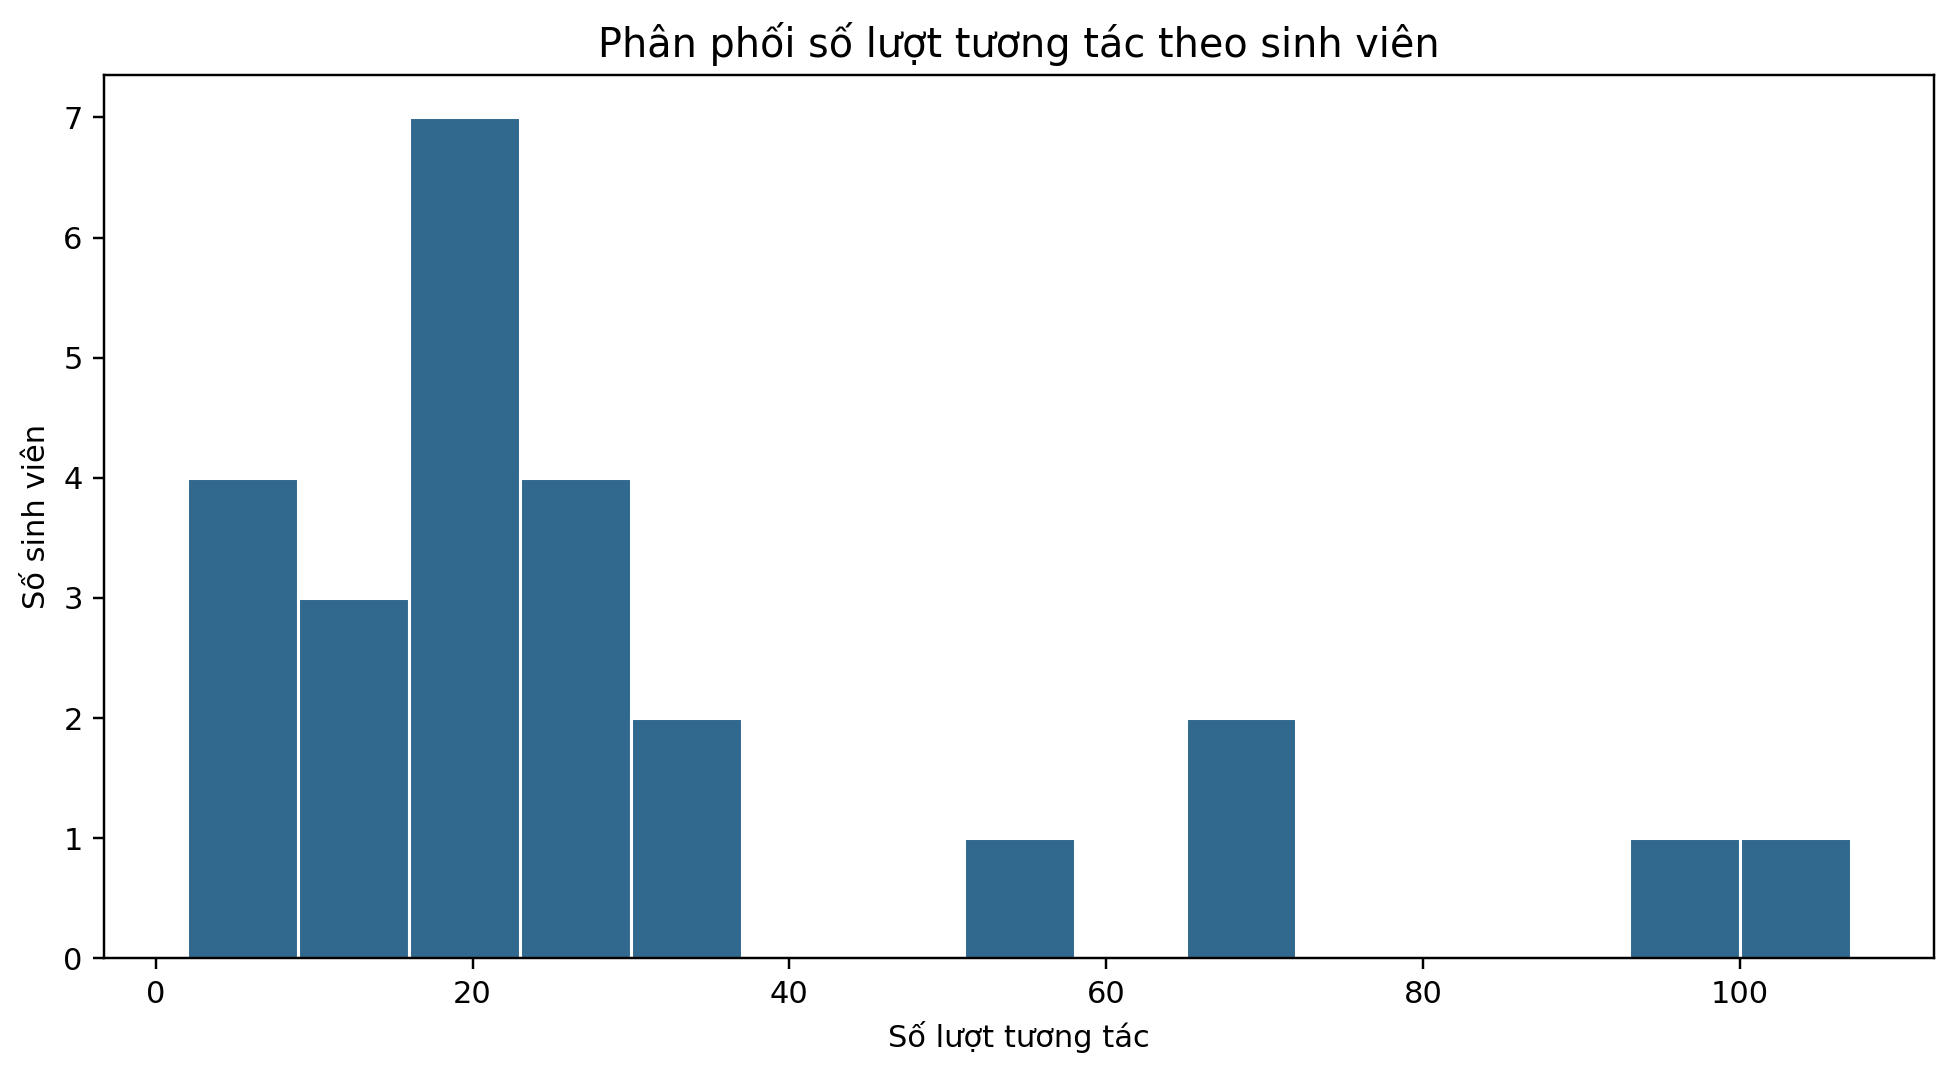

Đã quan sát 25 sinh viên; trung vị có 19 lượt tương tác và mức cao nhất là 107. Biểu đồ cho thấy độ dài lịch sử học tập trong phạm vi dữ liệu được quét.

### 02_dung_sai.png

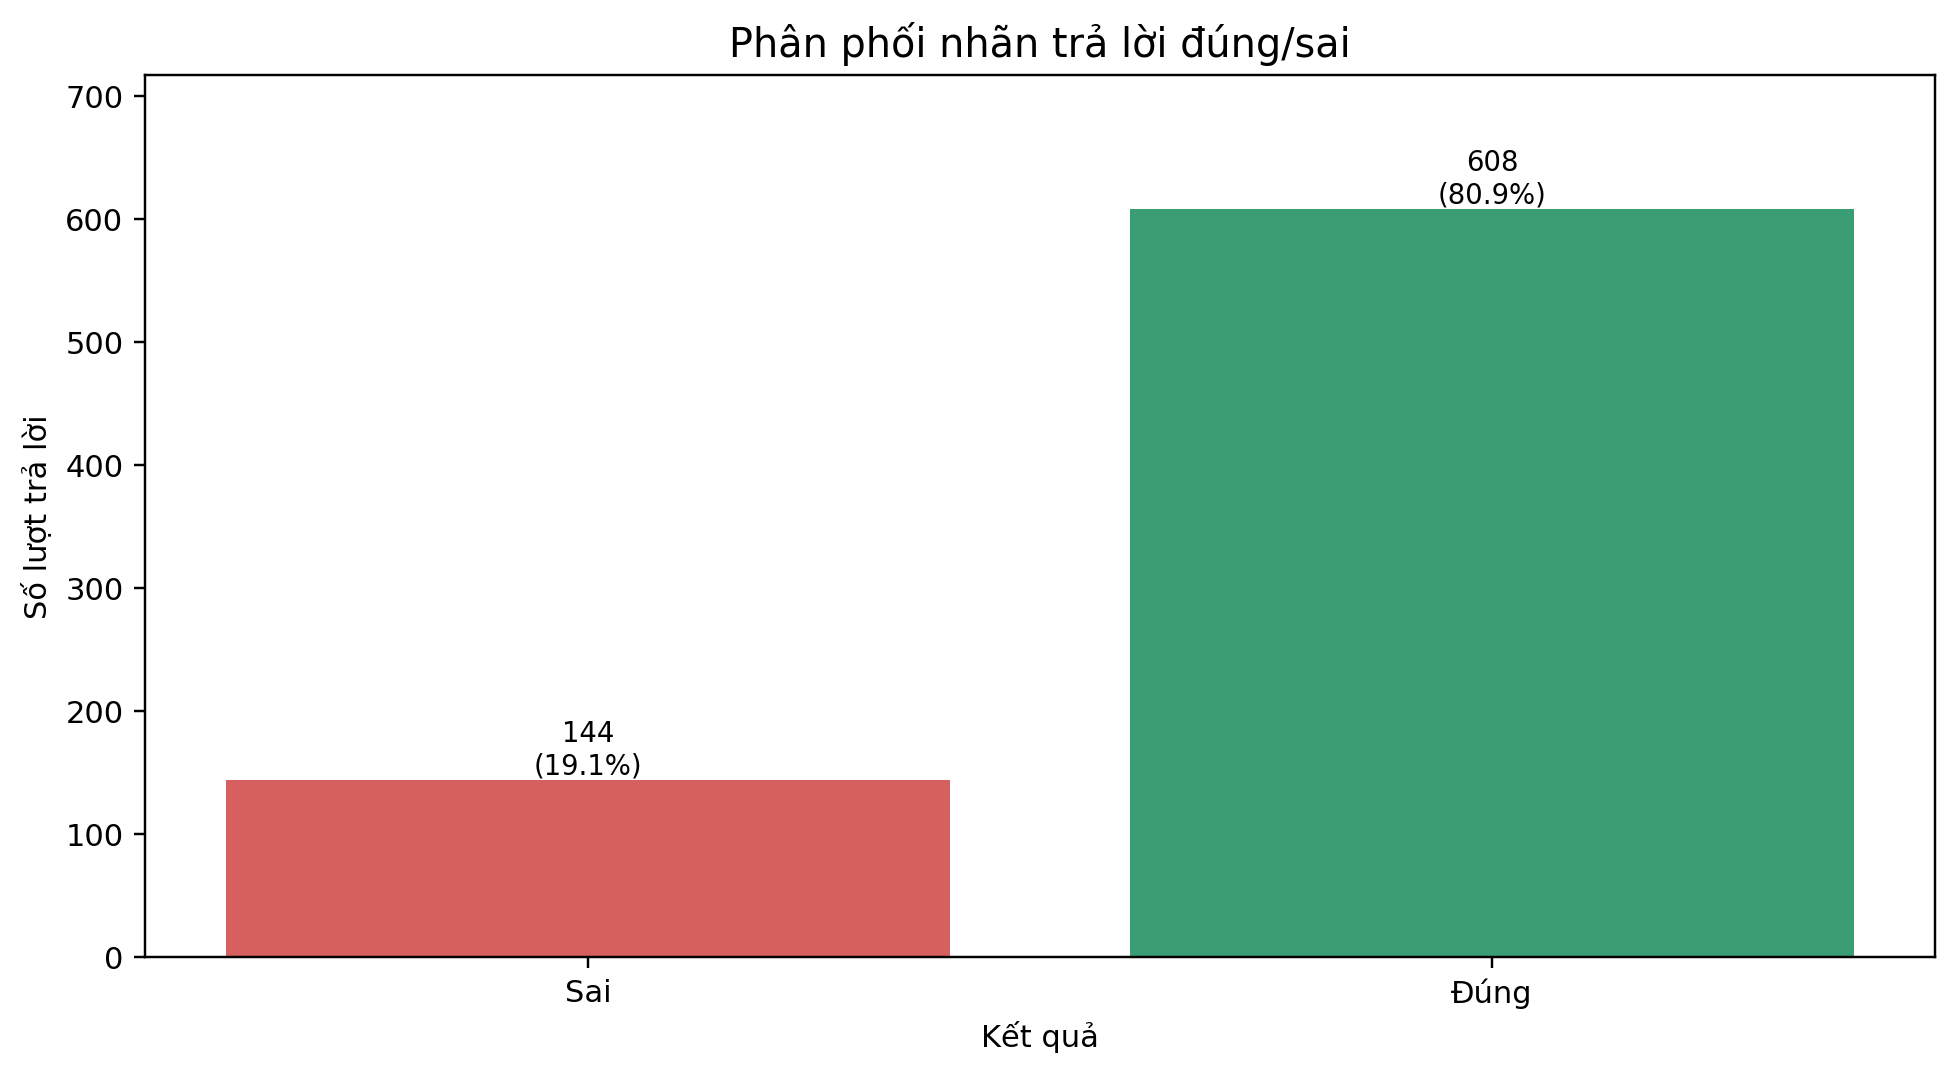

Tỷ lệ trả lời đúng là 80.9% trên 752 lượt có nhãn hợp lệ. Khi đánh giá mô hình cần xem thêm ROC-AUC/Brier bên cạnh accuracy.

### 03_tan_suat_concept.png

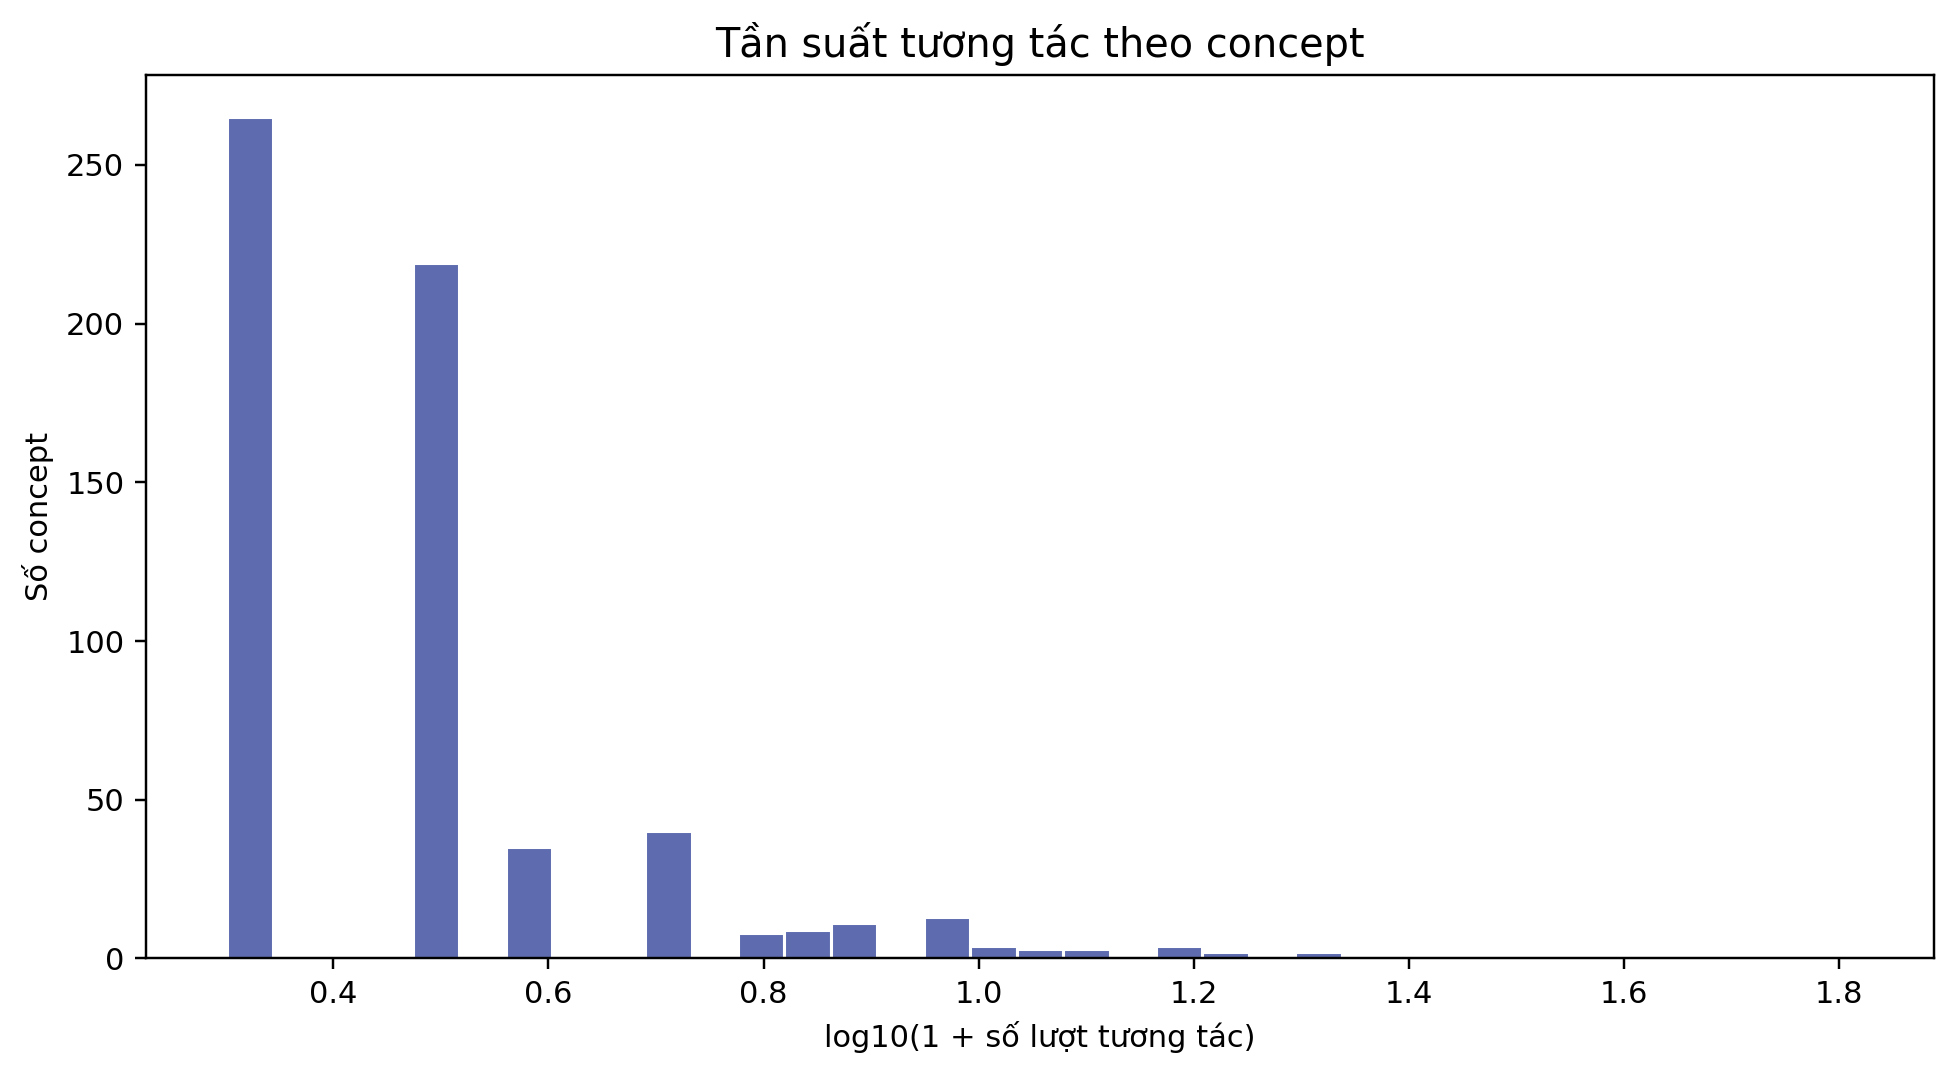

Có 622 concept xuất hiện trong các lượt trả lời đã quét. Trục ngang dùng log để quan sát cả concept hiếm và phổ biến; một lượt làm bài có thể đóng góp cho nhiều concept.

### 04_concept_ty_le_sai_cao.png

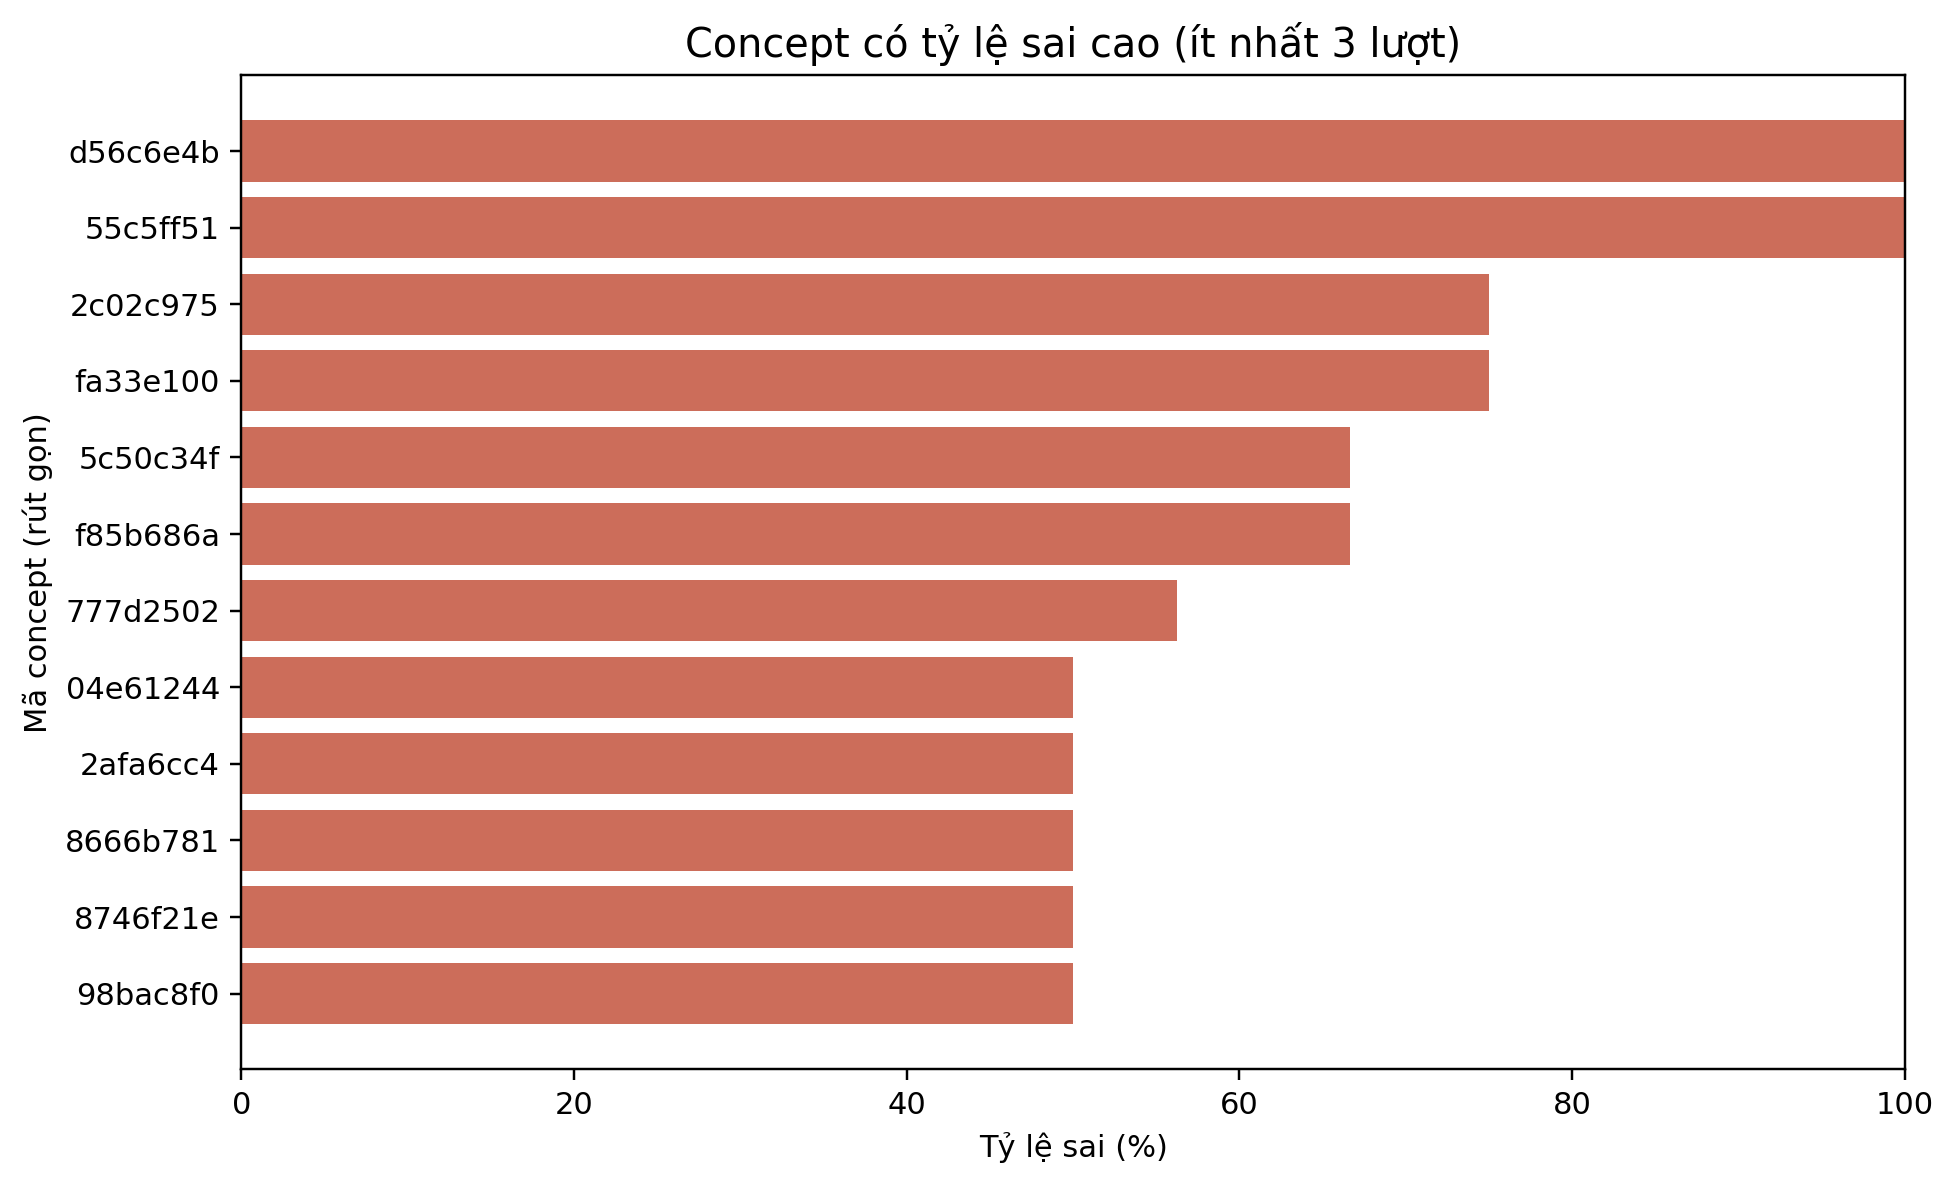

Biểu đồ chỉ xét concept có ít nhất 3 lượt để giảm nhiễu do cỡ mẫu quá nhỏ. Mức sai cao nhất trong nhóm này là 100.0%; cần xem số lượt cụ thể trong concept_statistics.csv trước khi kết luận.

In [14]:
plot_dir = run_dir / "plots/eda"
for name, note in list(report["plot_notes"].items())[:4]:
    display(Markdown(f"### {name}"))
    display(Image(filename=str(plot_dir / name), width=850))
    display(Markdown(note))


### 05_bloom_phan_phoi.png

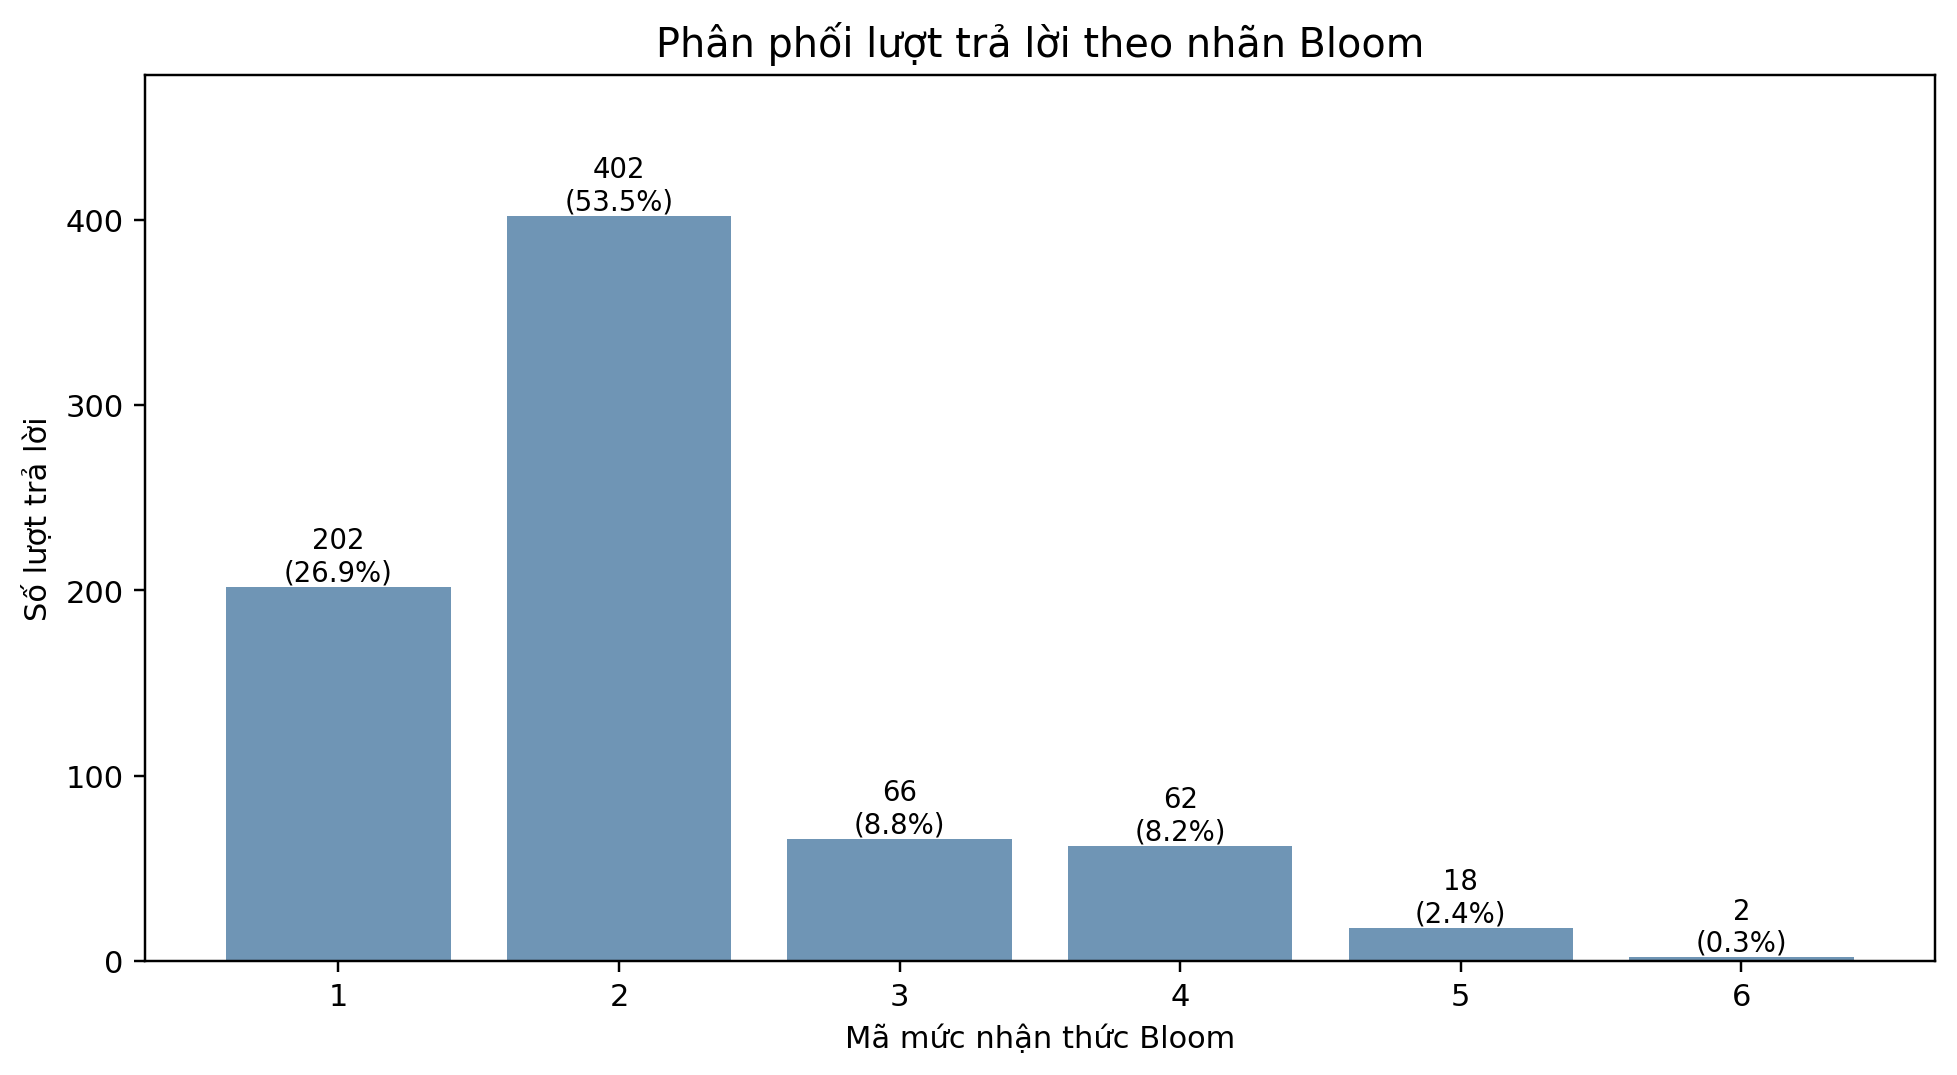

Có 752 lượt trả lời liên kết với nhãn Bloom hợp lệ. Các mã 1–6 được giữ nguyên vì file cục bộ không cung cấp bảng ánh xạ tên mức nhận thức.

### 06_bloom_ty_le_dung.png

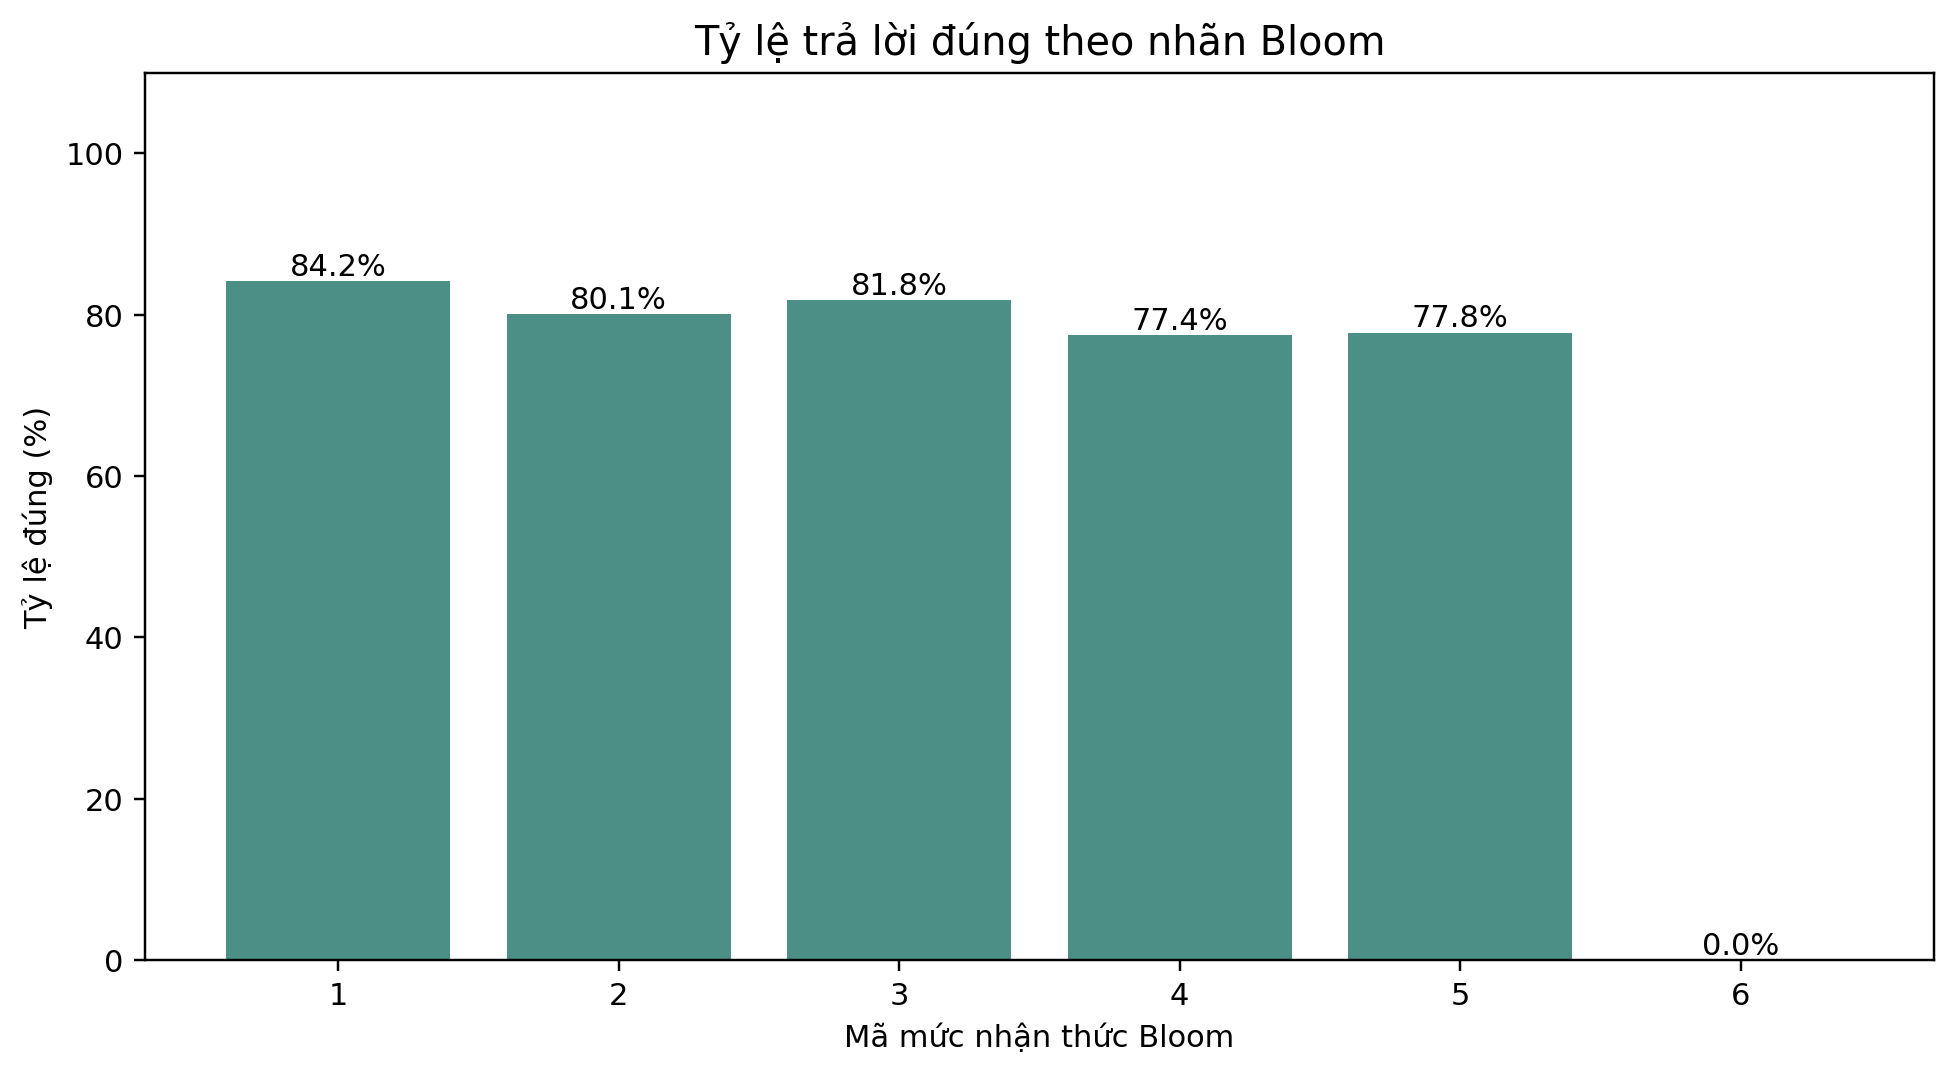

Tỷ lệ đúng được tính từ nhãn câu hỏi và kết quả trả lời thực tế. Chỉ số này không tự chứng minh năng lực Bloom của từng sinh viên.

### 07_tuong_tac_theo_thang.png

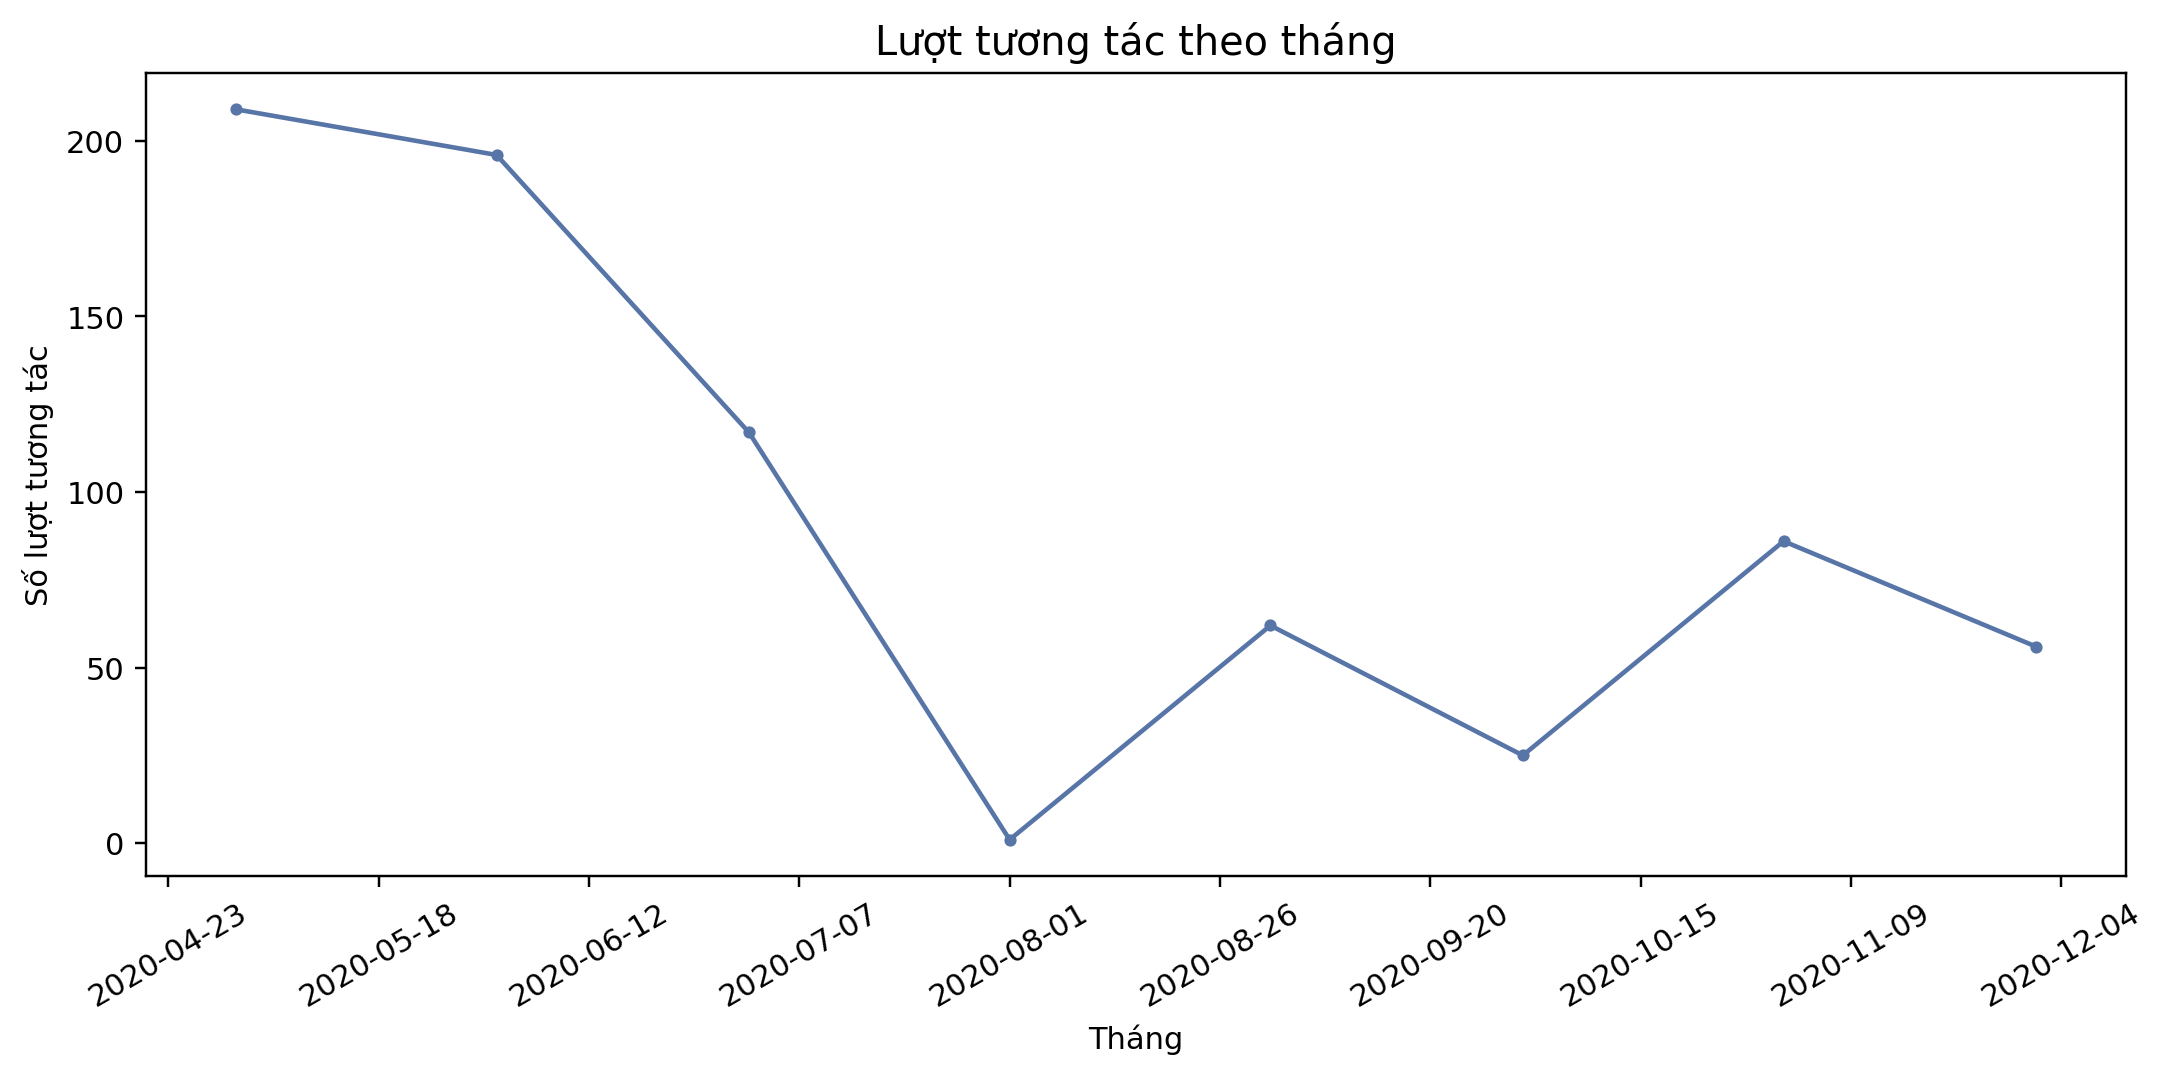

Dữ liệu có timestamp hợp lệ trải từ 2020-05 đến 2020-12. Biểu đồ mô tả thời điểm ghi nhận tương tác, không đo tiến bộ học tập.

### 08_khoa_hoc_nhieu_tuong_tac.png

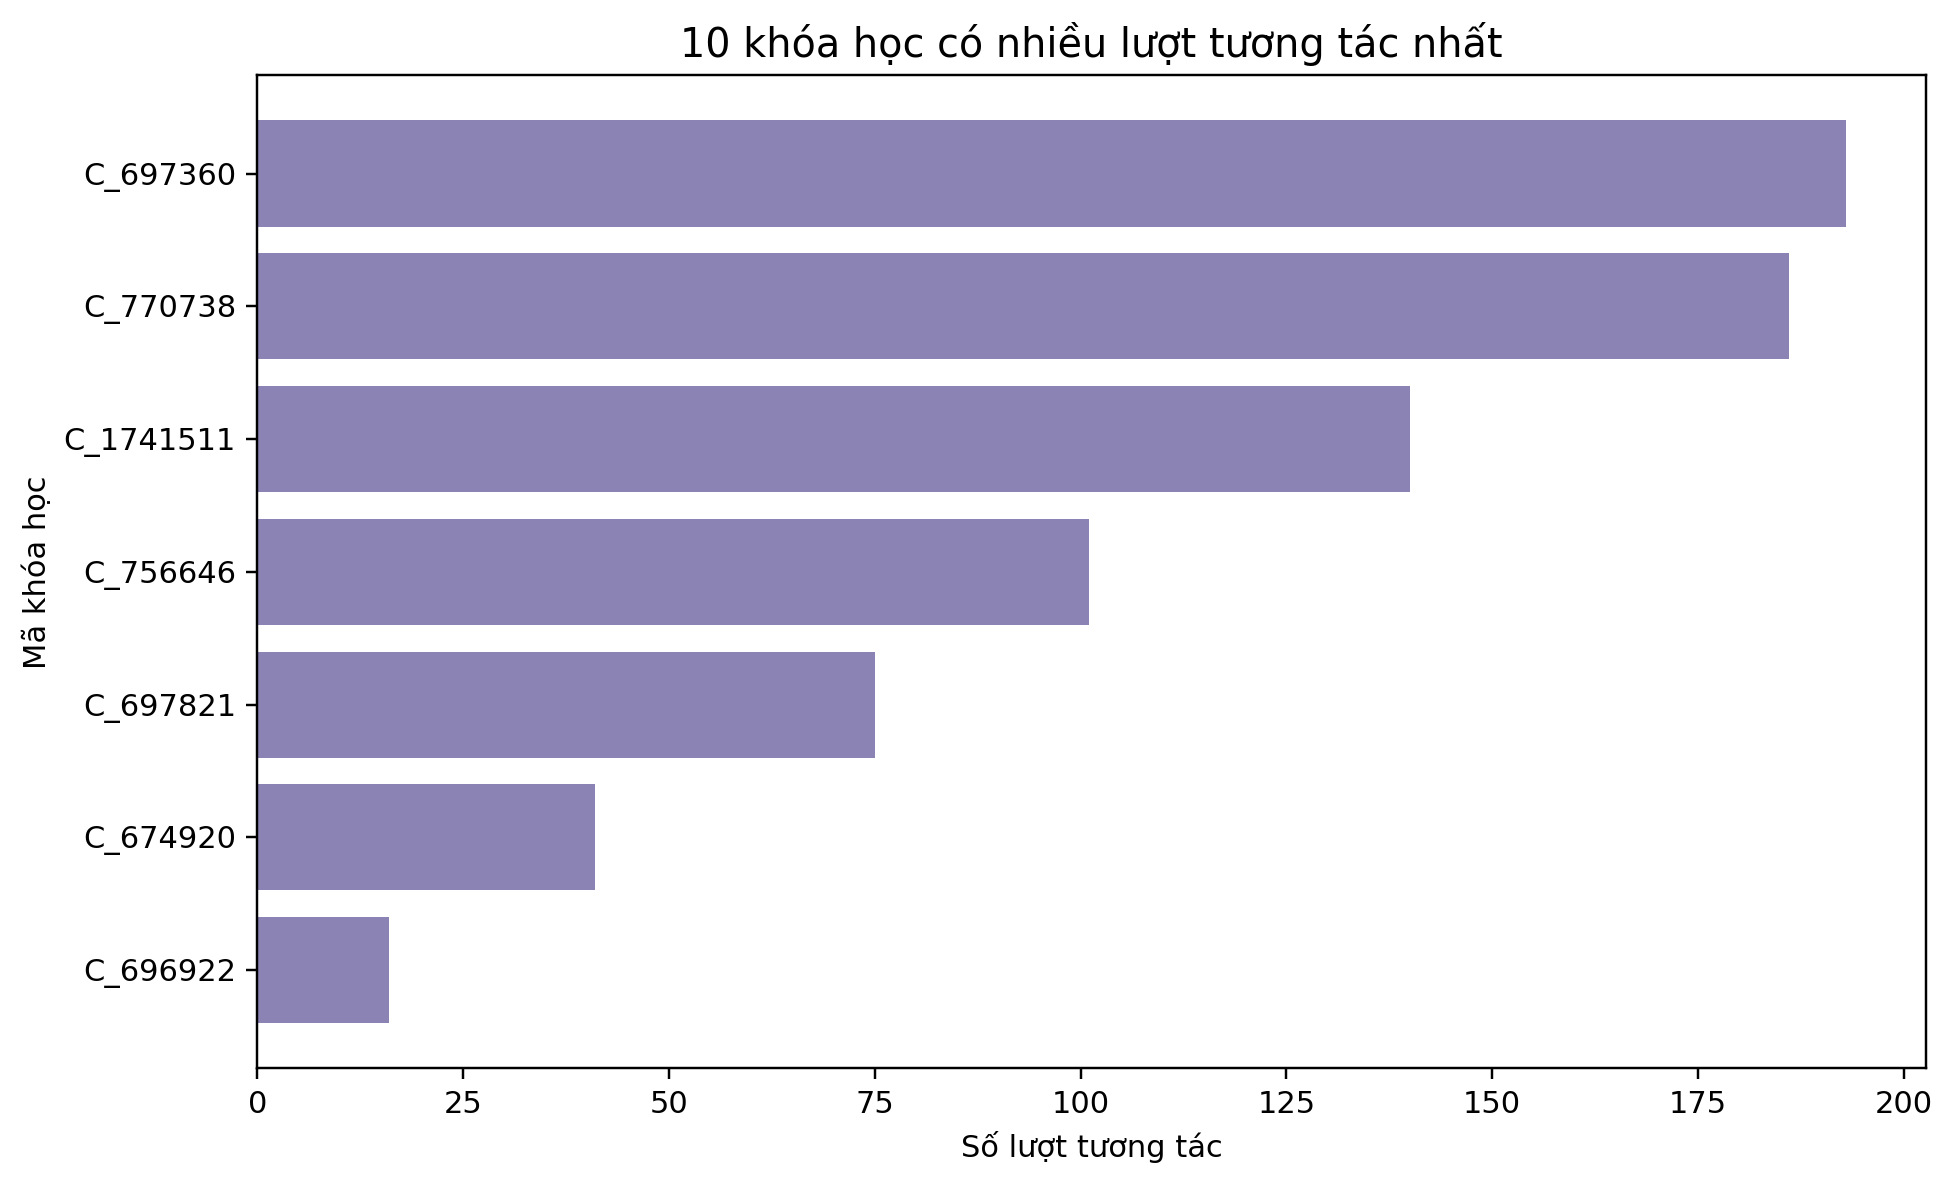

Khóa học có nhiều tương tác nhất ghi nhận 193 lượt trong phạm vi đã quét. Tần suất này không phản ánh trực tiếp chất lượng khóa học.

In [15]:
for name, note in list(report["plot_notes"].items())[4:]:
    display(Markdown(f"### {name}"))
    display(Image(filename=str(plot_dir / name), width=850))
    display(Markdown(note))


## 7. Tổng hợp các phát hiện chính

Báo cáo sau được tạo từ dữ liệu đã quét. Nếu đang dùng chế độ mẫu, không khái quát tỷ lệ tương tác cho toàn bộ sinh viên; chuyển sang `full` trước khi trích dẫn số liệu tổng thể trong báo cáo môn học.


In [16]:
summary_text = (run_dir / "eda_summary.md").read_text(encoding="utf-8")
display(Markdown(summary_text.split("## Khuyến nghị preprocessing")[0]))


# Tệp: eda_summary.md
# Mục đích: Tóm tắt đánh giá chất lượng dữ liệu và EDA từ dữ liệu thực.

# Tổng hợp chất lượng dữ liệu và EDA

**Phạm vi:** Chế độ mẫu: 25 chuỗi sinh viên đầu tiên; problem metadata được đọc đầy đủ. Các tỷ lệ tương tác chỉ mô tả mẫu.

## Tổng quan

- 9,383 problem metadata; 25 chuỗi sinh viên; 752 lượt trả lời.
- 4 file dữ liệu gốc được tìm thấy.
- 25 sinh viên, 401 bài có tương tác, 73 khóa học và 9,985 concept trong metadata.
- Độ dài chuỗi gốc: nhỏ nhất 2, trung vị 19, lớn nhất 107 lượt.

## Vấn đề chất lượng

- `score` thiếu ở 208/752 lượt (27.66%).
- Trùng `log_id`: 0; bản ghi trùng hoàn toàn: 0. Quan hệ một bài–nhiều concept không được tính là bản ghi trùng.
- Có 11 chuỗi và 41 cặp thời gian không theo thứ tự gốc.
- Timestamp không hợp lệ: 0; nhãn đúng/sai bất thường: 0.
- Giá trị `score` âm/không hợp lệ: 0; điểm lớn hơn mức tối đa ghi trong metadata: 0. Cần kiểm tra quy ước giá trị đặc biệt trước khi chuyển đổi.
- Lượt không nối được với problem metadata: 0; lượt thiếu liên kết concept: 0.
- Problem có nhiều concept: 7,203; độ bao phủ Bloom ở cấp lượt: 100.00%.
- Không thấy trường video có liên kết tường minh trong metadata cục bộ; độ bao phủ video được ghi nhận là 0% theo tiêu chí này.

## Phát hiện từ biểu đồ

- **01_tuong_tac_sinh_vien.png:** Đã quan sát 25 sinh viên; trung vị có 19 lượt tương tác và mức cao nhất là 107. Biểu đồ cho thấy độ dài lịch sử học tập trong phạm vi dữ liệu được quét.
- **02_dung_sai.png:** Tỷ lệ trả lời đúng là 80.9% trên 752 lượt có nhãn hợp lệ. Khi đánh giá mô hình cần xem thêm ROC-AUC/Brier bên cạnh accuracy.
- **03_tan_suat_concept.png:** Có 622 concept xuất hiện trong các lượt trả lời đã quét. Trục ngang dùng log để quan sát cả concept hiếm và phổ biến; một lượt làm bài có thể đóng góp cho nhiều concept.
- **04_concept_ty_le_sai_cao.png:** Biểu đồ chỉ xét concept có ít nhất 3 lượt để giảm nhiễu do cỡ mẫu quá nhỏ. Mức sai cao nhất trong nhóm này là 100.0%; cần xem số lượt cụ thể trong concept_statistics.csv trước khi kết luận.
- **05_bloom_phan_phoi.png:** Có 752 lượt trả lời liên kết với nhãn Bloom hợp lệ. Các mã 1–6 được giữ nguyên vì file cục bộ không cung cấp bảng ánh xạ tên mức nhận thức.
- **06_bloom_ty_le_dung.png:** Tỷ lệ đúng được tính từ nhãn câu hỏi và kết quả trả lời thực tế. Chỉ số này không tự chứng minh năng lực Bloom của từng sinh viên.
- **07_tuong_tac_theo_thang.png:** Dữ liệu có timestamp hợp lệ trải từ 2020-05 đến 2020-12. Biểu đồ mô tả thời điểm ghi nhận tương tác, không đo tiến bộ học tập.
- **08_khoa_hoc_nhieu_tuong_tac.png:** Khóa học có nhiều tương tác nhất ghi nhận 193 lượt trong phạm vi đã quét. Tần suất này không phản ánh trực tiếp chất lượng khóa học.

## Ảnh hưởng đến modeling

Thiếu `score` làm giảm khả năng dùng điểm số liên tục; nhãn `is_correct` vẫn có thể dùng khi hợp lệ. Mất cân bằng nhãn có thể khiến accuracy đánh lừa. Các chuỗi sai thứ tự thời gian có thể gây leakage nếu chia dữ liệu theo vị trí gốc. Quan hệ nhiều concept cần được giữ riêng để mỗi lượt trả lời chỉ đóng góp một dự đoán ở cấp câu hỏi.



## 8. Khuyến nghị làm sạch và preprocessing

Đây là đề xuất xử lý, chưa phải hành động xóa/sửa dữ liệu trong notebook. Các quyết định modeling cần giữ quan hệ nhiều concept và ngăn nhãn tương lai đi vào feature lịch sử.


In [17]:
recommendations = summary_text.split("## Khuyến nghị preprocessing")[1].split("## Giới hạn diễn giải")[0]
display(Markdown("## Khuyến nghị preprocessing" + recommendations))


## Khuyến nghị preprocessing

1. Giữ `score` gốc và giá trị thiếu; sử dụng nhãn `is_correct` gốc cho bài toán dự đoán đúng/sai. Kiểm tra riêng các điểm âm như `-1.0` trước khi coi chúng là giá trị thiếu.
2. Kiểm tra trùng theo `log_id` và nội dung sự kiện trước khi quyết định loại bản ghi; giữ bảng liên kết nhiều-nhiều `problem_concepts`.
3. Sắp xếp ổn định từng chuỗi theo `submit_time` trước khi chia train/validation/test; không dùng nhãn tương lai để tạo feature.
4. Gắn cờ lượt thiếu metadata/concept; không gán mastery bằng 0 cho concept chưa quan sát.
5. Giữ mã Bloom 1–6 cho đến khi có bảng ánh xạ được xác minh; không suy diễn năng lực cá nhân chỉ từ nhãn bài tập.
6. Chỉ đề xuất video khi có bảng liên kết video–problem/concept được xác minh; hiện ưu tiên bài tập.



## 9. Xuất báo cáo và biểu đồ

Thư mục run chứa báo cáo JSON, bảng CSV, tóm tắt Markdown và các hình dưới `plots/eda/`. Có thể sao chép cả thư mục này cho thành viên làm dashboard hoặc đưa hình vào slide. File raw không bị chỉnh sửa.


In [18]:
required = ["manifest.json", "data_quality_report.json", "missing_values.csv", "dataset_statistics.csv", "concept_statistics.csv", "course_statistics.csv", "monthly_statistics.csv", "eda_summary.md"]
assert all((run_dir / name).is_file() for name in required)
assert list(plot_dir.glob("*.png")), "Chưa có biểu đồ"
for path in sorted(run_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(run_dir))


concept_statistics.csv
course_statistics.csv
data_quality_report.json
dataset_statistics.csv
eda_summary.md
manifest.json
missing_values.csv
monthly_statistics.csv
plots/eda/01_tuong_tac_sinh_vien.png
plots/eda/02_dung_sai.png
plots/eda/03_tan_suat_concept.png
plots/eda/04_concept_ty_le_sai_cao.png
plots/eda/05_bloom_phan_phoi.png
plots/eda/06_bloom_ty_le_dung.png
plots/eda/07_tuong_tac_theo_thang.png
plots/eda/08_khoa_hoc_nhieu_tuong_tac.png
plots/eda/README.md
